# 클래스/화자 t-SNE — XLS-R feature 구조 보기

캐시된 frozen XLS-R **1920-d feature**를 2D로 투영해, ① 국적(클래스)으로 갈리는지 ② 한 클래스 안에서 **화자**로 뭉치는지 확인합니다.
feature: `feature_resplit_61_merged6_seed42_target_counts/train.npz` (X, y, speaker).

In [1]:
import os, json
import numpy as np
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt, matplotlib.font_manager as fm
fm.fontManager.addfont("$NATIONALITY_OUTPUTS/fonts/NotoSansKR.ttf")
plt.rcParams["font.family"]=fm.FontProperties(fname="$NATIONALITY_OUTPUTS/fonts/NotoSansKR.ttf").get_name()
plt.rcParams["axes.unicode_minus"]=False

TC="$NATIONALITY_OUTPUTS/feature_resplit_61_merged6_seed42_target_counts"
id2label=json.load(open(os.path.join(TC,"id2label.json"),encoding="utf-8"))
label2id={v:int(k) for k,v in id2label.items()}
z=np.load(os.path.join(TC,"train.npz"),allow_pickle=True)
X=z["X"]; y=z["y"]; spk=z["speaker"].astype(str)
rng=np.random.default_rng(0)
print("loaded", X.shape)

loaded (825409, 1920)


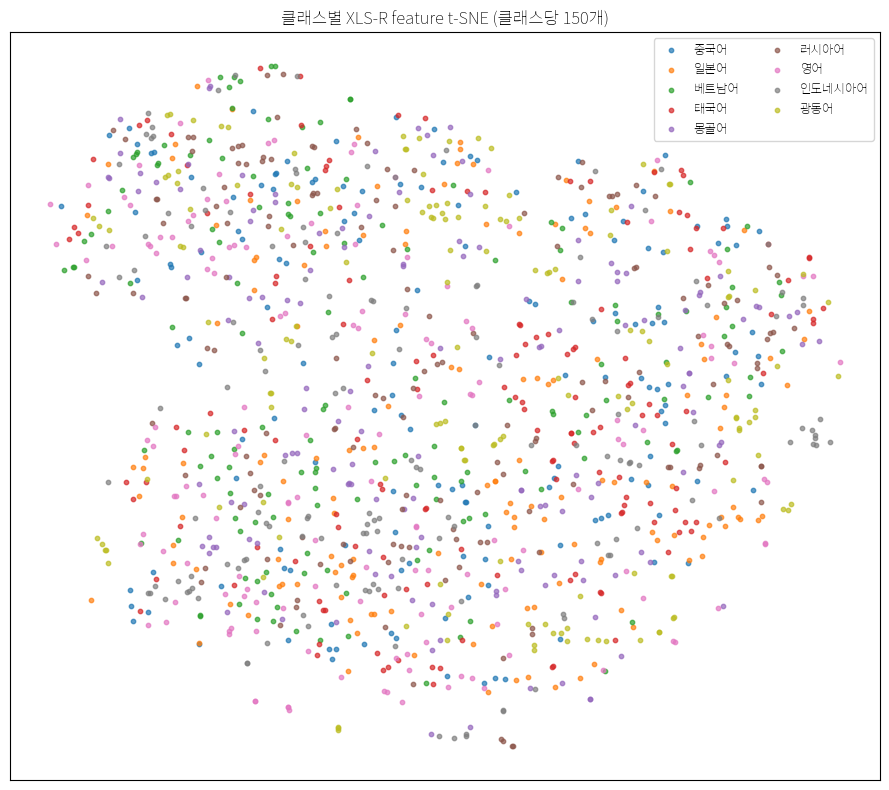

In [2]:
# ① 클래스별 t-SNE
CLASSES=["중국어","일본어","베트남어","태국어","몽골어","러시아어","영어","인도네시아어","광동어"]
PERCLS=150
idxs=[]; labs=[]
for c in CLASSES:
    pool=np.where(y==label2id[c])[0]
    take=rng.choice(pool,min(PERCLS,len(pool)),replace=False)
    idxs.append(take); labs+=[c]*len(take)
idxs=np.concatenate(idxs)
emb=TSNE(n_components=2,perplexity=30,init="pca",random_state=0).fit_transform(X[idxs].astype(np.float32))
labs=np.array(labs); cmap=plt.cm.tab10
fig,ax=plt.subplots(figsize=(9,8))
for i,c in enumerate(CLASSES):
    m=labs==c; ax.scatter(emb[m,0],emb[m,1],s=10,color=cmap(i%10),label=c,alpha=.7)
ax.legend(ncol=2,fontsize=9); ax.set_title("클래스별 XLS-R feature t-SNE (클래스당 150개)")
ax.set_xticks([]); ax.set_yticks([]); plt.tight_layout(); plt.show()

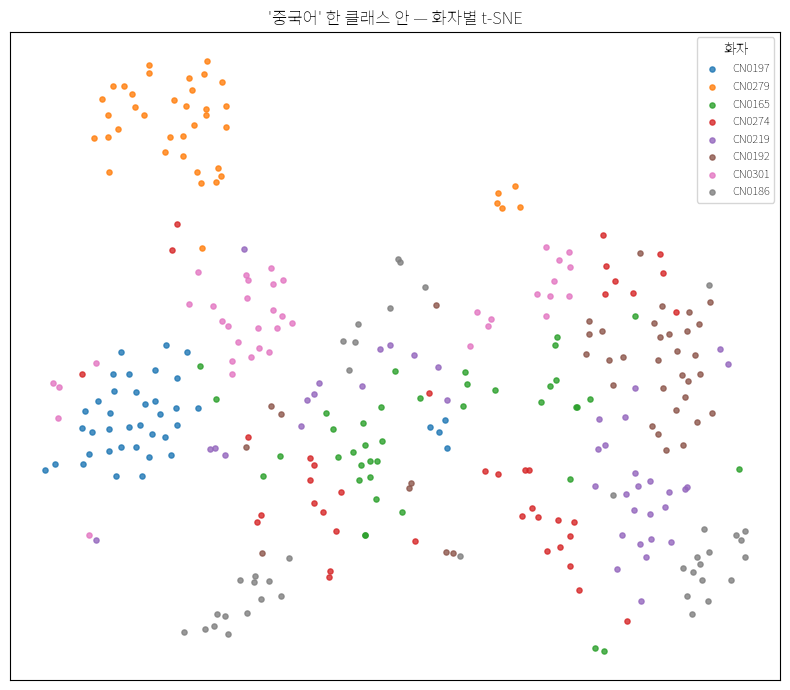

In [3]:
# ② 한 클래스 안 화자별 t-SNE (화자 혼입 확인)
TARGET="중국어"; N_SPK=8; PER=40
pool=np.where(y==label2id[TARGET])[0]
sp,cn=np.unique(spk[pool],return_counts=True); top=sp[np.argsort(-cn)[:N_SPK]]
idxs2=[]; labs2=[]
for s in top:
    p=pool[spk[pool]==s]; take=rng.choice(p,min(PER,len(p)),replace=False)
    idxs2.append(take); labs2+=[s]*len(take)
idxs2=np.concatenate(idxs2)
emb2=TSNE(n_components=2,perplexity=30,init="pca",random_state=0).fit_transform(X[idxs2].astype(np.float32))
labs2=np.array(labs2)
fig,ax=plt.subplots(figsize=(8,7))
for i,s in enumerate(top):
    m=labs2==s; ax.scatter(emb2[m,0],emb2[m,1],s=14,color=cmap(i%10),label=s,alpha=.8)
ax.legend(fontsize=8,title="화자"); ax.set_title(f"'{TARGET}' 한 클래스 안 — 화자별 t-SNE")
ax.set_xticks([]); ax.set_yticks([]); plt.tight_layout(); plt.show()

## 해석
- **①이 뒤섞임** = frozen feature의 가장 큰 변동이 국적이 아님.
- **②가 화자별로 뭉침** = feature가 화자를 강하게 인코딩.
- → **표현이 화자 지배적, 국적은 약하게 묻힘.** 화자 1명 클래스가 0%인 근본 원인.
- `CLASSES`/`TARGET` 바꿔 다른 조합도 확인 가능.